# 6 · Four models on the same questions

*Part 6 of the story. Previously: `05_cross_cutting.ipynb`.*

**What this notebook answers.** The pilot's core question - does dictionary
context help, and does graph-ranked context help more - was asked of four
models: two hosted API models (the pilot's base model `openai/gpt-6-luna` and,
on request, `google/gemini-4-argon`) and the two Slovene GaMS 12B models that
are reachable only through the povejmo.si chat (`GaMS3-12B-Instruct` and
`GaMS3-12B-RAG`, its retrieval-augmented sibling). Same questions, same
variants, same contexts - only the model changes.

**The caveat that shapes everything below.** The API runs are deterministic
(temperature 0, cached); the GaMS answers are *product observations* of a hosted
chat: single-sample, served model version not pinned, and not deterministic. A
repeatability check (the same 12 prompts re-sent to each GaMS model, last
section of this notebook) changed the cited sense id in about 1 of 12 cases.
With 36 questions that means: **differences of one or two questions (3-6 pp)
between models are noise**; only larger gaps are interpretable.

In [1]:
import csv
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import elexai.analysis as al

al.scientific_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)

API = al.find_run("skeleton")
GEM = al.find_run("gemini4-argon")
INSTR = al.find_run("gams3-12b")
RAG = al.find_run("gams3-12b-rag")
RUNS = [API, GEM, INSTR, RAG]
SHORT = {
    API: "API base (luna)",
    GEM: "Gemini 4 Argon",
    INSTR: "GaMS 12B-Instruct",
    RAG: "GaMS 12B-RAG",
}

acc = al.accuracy_frame(RUNS)
acc["model"] = acc["run_id"].map(SHORT)
acc = acc[acc["variant"].isin(["A", "B", "C", "D", "oracle"])]
acc[["run_id", "model", "variant", "n", "citation_accuracy", "answer_f1_mean"]]

,run_id,model,variant,n,citation_accuracy,answer_f1_mean
0,20261022-091557_skeleton,API base (luna),A,36,NaN,0.144
1,20261022-091557_skeleton,API base (luna),B,36,0.306,0.275
2,20261022-091557_skeleton,API base (luna),C,36,0.944,0.418
3,20261022-091557_skeleton,API base (luna),D,36,0.944,0.411
4,20261022-091557_skeleton,API base (luna),oracle,36,0.944,0.431
5,20261031-130253_gemini4-argon,Gemini 4 Argon,A,36,NaN,0.144
6,20261031-130253_gemini4-argon,Gemini 4 Argon,B,36,0.306,0.174
7,20261031-130253_gemini4-argon,Gemini 4 Argon,C,36,0.972,0.236
8,20261031-130253_gemini4-argon,Gemini 4 Argon,D,36,0.972,0.265
9,20261031-130253_gemini4-argon,Gemini 4 Argon,oracle,36,0.944,0.239


## Headline: citation accuracy by variant and model

`A` = base model, no context; `B` = our text RAG; `C` = the dictionary
candidate list (dictionary order); `D` = the same list re-ranked by the graph;
`oracle` = the gold sense shown (the composition ceiling).

In [2]:
order = ["B", "C", "D", "oracle"]
cite = acc.pivot_table(index="variant", columns="model", values="citation_accuracy").reindex(order)
excl = acc.pivot_table(index="variant", columns="model", values="citation_accuracy_excl_trick").reindex(order)
f1 = acc.pivot_table(index="variant", columns="model", values="answer_f1_mean")

print("citation accuracy - all 36 questions")
print(cite.round(3).to_string())
print("\ncitation accuracy - trick questions excluded (34)")
print(excl.round(3).to_string())
print("\nanswer-text token F1 (mean, vs the draft gold answer; A has no citation)")
print(f1.round(3).to_string())

citation accuracy - all 36 questions
model    API base (luna)  GaMS 12B-Instruct  GaMS 12B-RAG  Gemini 4 Argon
variant                                                                  
B                  0.306              0.306         0.250           0.306
C                  0.944              0.861         0.833           0.972
D                  0.944              0.806         0.806           0.972
oracle             0.944              0.861         0.806           0.944

citation accuracy - trick questions excluded (34)
model    API base (luna)  GaMS 12B-Instruct  GaMS 12B-RAG  Gemini 4 Argon
variant                                                                  
B                  0.294              0.294         0.235           0.294
C                  1.000              0.882         0.853           1.000
D                  1.000              0.853         0.824           1.000
oracle             1.000              0.882         0.853           1.000

answer-text token F1 (m

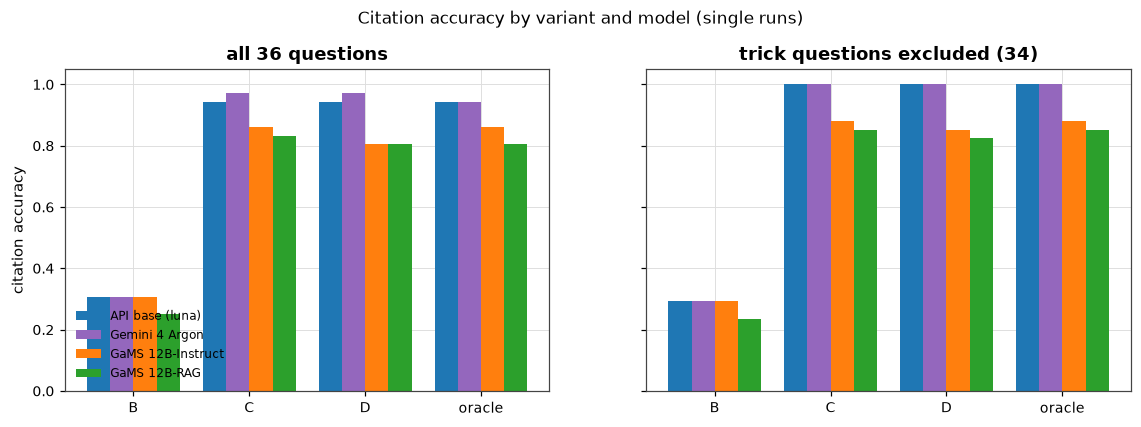

In [3]:
variants = ["B", "C", "D", "oracle"]
models = ["API base (luna)", "Gemini 4 Argon", "GaMS 12B-Instruct", "GaMS 12B-RAG"]
colors = ["#1f77b4", "#9467bd", "#ff7f0e", "#2ca02c"]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
for ax, title, piv in [
    (axes[0], "all 36 questions", cite),
    (axes[1], "trick questions excluded (34)", excl),
]:
    x = np.arange(len(variants))
    for i, (m, c) in enumerate(zip(models, colors, strict=True)):
        vals = [float(piv.loc[v, m]) for v in variants]
        ax.bar(x + (i - 1.5) * 0.2, vals, width=0.2, color=c, label=m)
    ax.set_xticks(x)
    ax.set_xticklabels(variants)
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("citation accuracy")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Citation accuracy by variant and model (single runs)", y=1.02, fontsize=11)
al.save_figure(fig, "06_citation_by_model")
plt.show()

> **Reading the chart.** Four things stand out.
>
> 1. **B is the same story everywhere** (0.25-0.31): when our text retriever
>    fails to fetch the gold sense (22 of 36 questions), no model - however
>    strong - can cite it. The bottleneck is retrieval, not the model.
> 2. **Gemini 4 Argon is the strongest model on the full task** (0.972 / 1.000
>    excluding trick items): the one question it misses is a known-flawed trick
>    item. Its language advantage shows up exactly where the base API model also
>    succeeds - and it is the only model that survives the trick questions.
> 3. **C lifts every model - but by different amounts.** The API models reach
>    0.94-0.97; the GaMS models ~0.83-0.86. A dictionary list is usable context
>    for a 12B Slovene model, but the large models exploit it better.
> 4. **D and oracle equal C for the GaMS models.** Their remaining errors are
>    *composition* errors: the gold sense is on the list (coverage is complete)
>    and they still pick a neighbour. Re-ranking cannot fix that - which is why
>    D adds nothing here (within noise, see the last section).

## Where the remaining errors come from

For every variant we can say *why* an answer was wrong: for B, the gold sense
was not retrieved at all (retrieval error); for C/D/oracle the gold sense was
shown but the model cited a different sense (composition error).

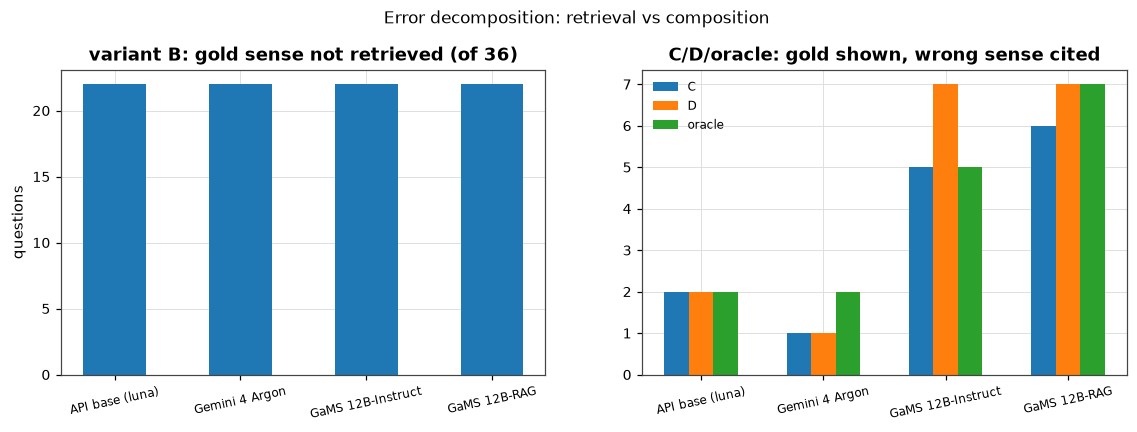

In [4]:
errors = []
for run in RUNS:
    m = al.load_metrics(run)
    for v in ["B", "C", "D", "oracle"]:
        e = m["variants"][v]
        errors.append(
            {
                "model": SHORT[run],
                "variant": v,
                "gold_not_retrieved": e.get("retrieval_errors", 0) if v == "B" else 0,
                "gold_shown_wrong_sense": e.get("composition_errors", 0) if v != "B" else 0,
            }
        )
err = pd.DataFrame(errors)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
x = np.arange(len(models))
label_models = models
b = [
    int(err[(err["model"] == m) & (err["variant"] == "B")]["gold_not_retrieved"].sum())
    for m in label_models
]
axes[0].bar(x, b, color="#1f77b4", width=0.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(label_models, fontsize=8, rotation=12)
axes[0].set_title("variant B: gold sense not retrieved (of 36)")
axes[0].set_ylabel("questions")

width = 0.2
for i, v in enumerate(["C", "D", "oracle"]):
    vals = [
        int(err[(err["model"] == m) & (err["variant"] == v)]["gold_shown_wrong_sense"].sum())
        for m in label_models
    ]
    axes[1].bar(x + (i - 1) * width, vals, width=width, label=v)
axes[1].set_xticks(x)
axes[1].set_xticklabels(label_models, fontsize=8, rotation=12)
axes[1].set_title("C/D/oracle: gold shown, wrong sense cited")
axes[1].legend(fontsize=8)
fig.suptitle("Error decomposition: retrieval vs composition", y=1.03, fontsize=11)
al.save_figure(fig, "06_error_decomposition")
plt.show()

> **Reading the chart.** Retrieval errors are identical for all four models
> (the retriever is ours). The composition residue is what separates them: the
> API models have 0-1 errors; both GaMS models have five to seven - even the
> oracle row fails on the same questions. That is the ceiling of what better
> retrieval or better ordering could achieve with these models on this set.

## The questions that beat the models

Every non-trick question where at least one model/variant failed.

In [5]:
cols = {}
for run in RUNS:
    df = al.load_answers(run)
    for v in ["C", "D"]:
        s = df[(df["variant"] == v) & (~df["is_trick"])].set_index("question_id")["correct"]
        cols[f"{SHORT[run]} {v}"] = s.fillna(False).astype(bool)
mat = pd.DataFrame(cols)

qs = al.load_questions_table().set_index("question_id")
hard = mat[~mat.all(axis=1)].join(qs[["lemma", "context_sentence", "gold_answer"]])
hard

,API base (luna) C,API base (luna) D,Gemini 4 Argon C,Gemini 4 Argon D,GaMS 12B-Instruct C,GaMS 12B-Instruct D,GaMS 12B-RAG C,GaMS 12B-RAG D,lemma,context_sentence,gold_answer
question_id,,,,,,,,,,,
q-011,True,True,True,True,False,False,False,False,jabolko,Novo jabolko je razočaralo številne kupce.,"neformalno poimenovanje za podjetje Apple ali za njegove izdelke, zlasti računalnike in telefone"
q-019,True,True,True,True,True,True,True,False,srce,Staro mestno jedro je srce mesta.,"osrednji, najpomembnejši del"
q-024,True,True,True,True,True,False,True,True,pero,Pero mehanske ure je počilo.,vzmet
q-025,True,True,True,True,False,False,False,False,list,Na tržnici prodajajo svežega morskega lista.,riba
q-026,True,True,True,True,False,False,False,False,jabolko,Staro jabolko na vrtu še vedno dobro rodi.,"sadno drevo, na katerem rastejo jabolka"
q-029,True,True,True,True,False,False,False,False,srce,Na rojstnodnevni voščilnici je narisala rdeče srce.,o obliki
q-030,True,True,True,True,True,True,False,False,obraz,Postal je znan obraz na televiziji.,o osebi


> **Reading the table.** The GaMS failures are not random words - they are
> *figurative, metonymic and idiomatic* uses of common nouns:
>
> - `q-011` *jabolko*: "Novo **jabolko** je razočaralo številne kupce." - the
>   Apple-brand sense (the fruit sense wins in both GaMS models);
> - `q-026` *jabolko*: "Staro **jabolko** na vrtu še vedno dobro rodi." - the
>   *tree*, not the fruit;
> - `q-025` *list*: "svežega **morskega lista**" - the fish *sole*, not a plant
>   leaf (both GaMS models read it literally even with the gold sense shown);
> - `q-029` *srce*: "narisala rdeče **srce**" - the *shape*, not the emotion;
> - `q-030` *obraz*: "znan **obraz** na televiziji" - a *person*, not a body part;
> - `q-019` *srce*: "**srce** mesta" - the central part;
> - `q-024` *pero*: "**Pero** mehanske ure je počilo." - the clock *spring*; this
>   is also the one question where the GaMS models flip between runs.
>
> The dictionary list gives the models the right candidates; recognising the
> figurative reading is the part they fail. That is exactly the boundary the
> oracle row exposes.

## How much can we trust the differences? (repeatability)

The API runs are deterministic (temperature 0, cached: re-running returns the
identical answer). The GaMS runs are single samples of a chat product; the same
12 prompts (six questions x variants C and D, chosen around the hard and the
flipping cases) were re-sent a day later and compared.

In [6]:
SENSE = re.compile(r"SENSE_ID:\s*(\d+|none)", re.IGNORECASE)


def load_csv(path: Path) -> dict:
    with path.open(encoding="utf-8-sig", newline="") as f:
        return {
            (r["question_id"], r["variant"]): (r["answer_raw"] or "").strip()
            for r in csv.DictReader(f)
        }


def cited(text: str) -> str:
    m = SENSE.search(text)
    return m.group(1).lower() if m else "?"


KIT = al.REPO_ROOT / "manual_kit"
pairs = [
    ("GaMS 12B-Instruct", KIT / "answers_repeat.csv", KIT / "answers_gams3-12b.csv"),
    ("GaMS 12B-RAG", KIT / "answers_repeat_rag.csv", KIT / "answers_gams3-12b-rag.csv"),
]
rows = []
for name, rep_path, orig_path in pairs:
    if not (rep_path.exists() and orig_path.exists()):
        rows.append({"model": name, "repeats": 0, "same cited id": "-", "identical text": "-", "flips": "repeatability files not available (manual_kit is local)"})
        continue
    rep, orig = load_csv(rep_path), load_csv(orig_path)
    same = sum(1 for k, t in rep.items() if t and cited(t) == cited(orig.get(k, "")))
    ident = sum(1 for k, t in rep.items() if t and t == orig.get(k, ""))
    flips = [
        f"{k[0]} {k[1]}: {cited(orig.get(k, ''))} -> {cited(t)}"
        for k, t in rep.items()
        if t and cited(t) != cited(orig.get(k, ""))
    ]
    rows.append(
        {
            "model": name,
            "repeats": len(rep),
            "same cited id": f"{same}/{len(rep)}",
            "identical text": f"{ident}/{len(rep)}",
            "flips": "; ".join(flips) or "-",
        }
    )
pd.DataFrame(rows)

,model,repeats,same cited id,identical text,flips
0,GaMS 12B-Instruct,12,10/12,0/12,q-024 C: 16255195 -> 16255190; q-024 D: 16255190 -> 16255195
1,GaMS 12B-RAG,12,12/12,3/12,-


> **Reading the table.** The cited sense id - the number all citation metrics
> use - is stable in ~92 % of repeats (22/24); every flip happened on `q-024`
> (*pero*), where the model swapped between the pen and the clock-spring sense
> in both directions. The answer *text* is almost never byte-identical
> (paraphrases), which matters only for the F1 column of variant A.
>
> **Rule used throughout this project:** on the 36-question set, a difference
> of one or two questions (3-6 pp) between models or variants is within the
> noise of a single chat run; only larger gaps are interpreted. The API runs
> (luna, Gemini) have no such noise - their differences are single questions
> between deterministic runs.

## What this adds up to

- **The dictionary candidate list helps every model, but not equally**: the API
  models reach 0.94 (0.97 for Gemini, 1.000 excluding the flawed trick items);
  the GaMS 12B models ~0.83-0.86. The gap lives in *figurative* sense
  recognition, not in access to the dictionary.
- **Gemini 4 Argon is the strongest model tested** (0.972 all / 1.000 excl.
  trick, single 36-question pass) - the language-strength claim from the
  project discussion holds on this task, and it is visible exactly where the
  other models fail (trick items, figurative uses).
- **The remaining GaMS errors are composition errors, not coverage errors**
  (oracle = C = 0.83-0.86): the list contains the right sense, the model picks a
  neighbour. Graph re-ranking (D) cannot help there - and measurably does not.
- **Variant B is retrieval-bound for every model** (22/36 misses; identical
  across models, because the retriever is ours). A better retriever, not a
  better model, is what would move B.
- **The povejmo.si "-RAG" mode does not improve on the plain Instruct model**
  on this task (all differences within the noise floor); its built-in retrieval
  does not replace the dictionary context.

## Limits and next steps

- Questions and gold answers are **drafts** until a lexicographer verifies them;
  the trick items (q-005, q-016) are known-flawed and excluded in the secondary
  numbers.
- The GaMS runs are **single samples** of a hosted product: version unpinned,
  temperature/decoding not controllable, latency not comparable (not logged).
  The repeatability check bounds the noise on 12 prompts, not on all 36.
- The **budget sweep** (candidate caps 1/2/3) and the payoff-rule analysis exist
  for the base API model (`03_when_does_the_graph_pay_off.ipynb`); running them
  for Gemini and the GaMS models would test whether the graph pays off where C
  is starved - the natural next experiment.
- `GaMS3-12B-Instruct-Lex` (continually pre-trained on DDD) and the local
  Q4 control are prepared (`docs/LOCAL_MODEL.md`): *dictionary in weights vs in
  context*.